<a href="https://colab.research.google.com/github/Aldiss1/MPPM_Aldi/blob/main/JS08/JS08-Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab 2 — HDBSCAN pada Dataset Nyata (`sklearn.datasets`)

Pengerjaan **JS08 Hierarchical Clustering — Tugas Lab 2** (Polinema, JTI Modul Praktikum Pembelajaran Mesin).

**Instruksi tugas:**
1. Pilih salah satu dataset nyata dari `sklearn.datasets` (misalnya **iris** atau **digits**).
2. Lakukan clustering dengan **HDBSCAN**.
3. Laporkan hasil: **jumlah cluster**, **banyaknya noise**, dan **visualisasi** (gunakan PCA/t-SNE untuk reduksi dimensi).
4. Buat **analisis singkat**: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset?

**Pilihan dataset:** iris dan digits — keduanya menunjukkan sifat HDBSCAN yang berbeda dan saling melengkapi:

| Dataset | Dimensi | Kelas asli | Yang ingin ditunjukkan |
|---|---|---|---|
| **Iris** | 4 fitur | 3 | HDBSCAN menemukan **lebih sedikit** cluster dari label asli (under-segmentation) |
| **Digits** | 64 fitur | 10 | HDBSCAN menemukan **lebih banyak** cluster dari label asli (over-segmentation) |


**Catatan:** label asli (`target`) **tidak dipakai** untuk membentuk cluster. Label hanya dipakai di akhir untuk mengevaluasi hasil.

## Persiapan — Library dan Fungsi Visualisasi

Fungsi `plot()` diambil **verbatim dari Lab 2 modul** agar konsisten: noise digambar sebagai tanda **x** hitam, anggota cluster sebagai **o** berwarna, dan ukuran marker sebanding dengan `probabilities_`.

In [1]:
# Jalankan sekali saja bila library belum tersedia
# !pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    adjusted_mutual_info_score,
    normalized_mutual_info_score,
    silhouette_score,
    davies_bouldin_score,
)
import hdbscan

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    """Fungsi visualisasi dari Lab 2 modul (tanpa perubahan)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0], X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()


def evaluasi(X, labels, nama=""):
    """Hitung jumlah cluster, noise, dan metrik. Noise (-1) DIKELUARKAN dari metrik."""
    labels = np.asarray(labels)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    n_noise = int((~mask).sum())
    sil = dbi = np.nan
    if n_clusters >= 2:
        sil = silhouette_score(X[mask], labels[mask])
        dbi = davies_bouldin_score(X[mask], labels[mask])
    return {
        "percobaan": nama,
        "n_clusters": n_clusters,
        "n_noise": n_noise,
        "persen_noise": 100 * n_noise / len(labels),
        "silhouette": sil,
        "dbi": dbi,
    }


def purity(labels, y_true):
    """Purity: proporsi anggota cluster yang berasal dari kelas mayoritas cluster tsb."""
    labels, y_true = np.asarray(labels), np.asarray(y_true)
    mask = labels != -1
    ct = pd.crosstab(labels[mask], y_true[mask])
    return ct.max(axis=1).sum() / ct.values.sum()

`purity` perlu dijelaskan karena akan sering dipakai: untuk setiap cluster, cari label asli yang paling dominan, lalu hitung berapa persen anggota cluster itu yang benar-benar berlabel demikian. Nilai **1,0** berarti setiap cluster hanya berisi satu kelas asli. Kelemahan purity adalah ia **tidak menghukum over-segmentation** — memecah satu kelas menjadi 10 cluster kecil tetap mendapat purity 1,0. Karena itu purity selalu dibaca bersama **ARI**.

---
# Bagian A — Dataset Iris

**150 bunga iris, 4 fitur** (panjang & lebar sepal dan petal), **3 kelas asli**: *setosa*, *versicolor*, *virginica*. Dataset ini klasik karena versicolor dan virginica **saling tumpang tindih** di ruang fitur — fakta yang akan sangat menentukan hasil HDBSCAN.

## A.1 — Load Dataset & Inspeksi

In [3]:
X_iris, y_iris = load_iris(return_X_y=True)
nama_kelas = np.array(["setosa", "versicolor", "virginica"])

print("Bentuk X:", X_iris.shape)
print("Jumlah kelas asli:", len(set(y_iris)))
print()
df_iris = pd.DataFrame(X_iris, columns=["sepal_length", "sepal_width", "petal_length", "petal_width"])
df_iris["species"] = nama_kelas[y_iris]
df_iris.head()

Bentuk X: (150, 4)
Jumlah kelas asli: 3



,sepal_length,sepal_width,petal_length,petal_width,species
0,5.100,3.500,1.400,0.200,setosa
1,4.900,3.000,1.400,0.200,setosa
2,4.700,3.200,1.300,0.200,setosa
3,4.600,3.100,1.500,0.200,setosa
4,5.000,3.600,1.400,0.200,setosa


In [4]:
print("Sebaran kelas asli:")
print(pd.Series(nama_kelas[y_iris]).value_counts().to_string())
print()
df_iris.describe().T

Sebaran kelas asli:
setosa        50
versicolor    50
virginica     50



,count,mean,std,min,25%,50%,75%,max
sepal_length,150.000,5.843,0.828,4.300,5.100,5.800,6.400,7.900
sepal_width,150.000,3.057,0.436,2.000,2.800,3.000,3.300,4.400
petal_length,150.000,3.758,1.765,1.000,1.600,4.350,5.100,6.900
petal_width,150.000,1.199,0.762,0.100,0.300,1.300,1.800,2.500


Dataset seimbang (50 per kelas), tanpa *missing value*. Keempat fitur satuannya sentimeter dengan rentang 0,1–7,9 — relatif sebanding, sehingga standardisasi di sini pengaruhnya kecil.

## A.2 — Standardisasi & Reduksi Dimensi dengan PCA

Data distandarisasi karena HDBSCAN berbasis jarak. PCA dipakai untuk **visualisasi** (4 dimensi tidak bisa diplot), bukan untuk clustering — clustering tetap memakai 4 fitur asli.

In [5]:
scaler_iris = StandardScaler()
X_iris_s = scaler_iris.fit_transform(X_iris)

pca_iris = PCA(n_components=2, random_state=0)
X_iris_pca = pca_iris.fit_transform(X_iris_s)

pca_iris3 = PCA(n_components=3, random_state=0)
X_iris_pca3 = pca_iris3.fit_transform(X_iris_s)

print("Variansi yang dijelaskan PCA 2 komponen:", np.round(pca_iris.explained_variance_ratio_, 4),
      f"-> total {pca_iris.explained_variance_ratio_.sum():.2%}")
print("Variansi yang dijelaskan PCA 3 komponen:",
      f"total {pca_iris3.explained_variance_ratio_.sum():.2%}")

Variansi yang dijelaskan PCA 2 komponen: [0.7296 0.2285] -> total 95.81%
Variansi yang dijelaskan PCA 3 komponen: total 99.48%


Dua komponen PCA sudah menangkap **95,8%** variansi, sehingga scatterplot 2D cukup mewakili struktur asli data 4 dimensi.

Sekilas perbandingan standardisasi vs tanpa standardisasi — untuk memastikan pilihan ini tidak mengubah kesimpulan:

In [6]:
for nama, data in [("tanpa standardisasi", X_iris), ("dengan standardisasi", X_iris_s)]:
    lab = hdbscan.HDBSCAN().fit_predict(data)
    nc = len(set(lab)) - (1 if -1 in lab else 0)
    print(f"{nama:22s}: cluster={nc}, noise={int((lab == -1).sum())}, ARI={adjusted_rand_score(y_iris, lab):.4f}")

tanpa standardisasi   : cluster=2, noise=0, ARI=0.5681
dengan standardisasi  : cluster=2, noise=2, ARI=0.5394


Hasilnya hampir identik (2 cluster, ARI ≈ 0,56), karena keempat fitur iris memang bersatuan sama dan berskala sebanding. Standardisasi tetap dipakai sebagai praktik baku untuk algoritma berbasis jarak.

## A.3 — Clustering dengan HDBSCAN

In [7]:
hdb_iris = hdbscan.HDBSCAN().fit(X_iris_s)
labels_iris = hdb_iris.labels_

n_clusters_iris = len(set(labels_iris)) - (1 if -1 in labels_iris else 0)
n_noise_iris = int((labels_iris == -1).sum())

print("=== HDBSCAN pada Iris (parameter default) ===")
print(f"Jumlah cluster : {n_clusters_iris}")
print(f"Jumlah noise   : {n_noise_iris} dari {len(labels_iris)} data ({100*n_noise_iris/len(labels_iris):.2f}%)")
print(f"Ukuran cluster : {np.bincount(labels_iris[labels_iris != -1]).tolist()}")
print(f"Persistence    : {np.round(hdb_iris.cluster_persistence_, 4).tolist()}")

=== HDBSCAN pada Iris (parameter default) ===
Jumlah cluster : 2
Jumlah noise   : 2 dari 150 data (1.33%)
Ukuran cluster : [99, 49]
Persistence    : [0.3058, 0.4606]


**Hasil: 2 cluster, 2 noise.** Label aslinya ada **3 kelas**, jadi HDBSCAN menemukan **lebih sedikit** cluster daripada yang diharapkan.

## A.4 — Membandingkan Hasil Cluster dengan Label Asli

In [8]:
tabel_iris = pd.crosstab(
    pd.Series(labels_iris, name="cluster_HDBSCAN"),
    pd.Series(nama_kelas[y_iris], name="spesies_asli"),
)
tabel_iris

spesies_asli,setosa,versicolor,virginica
cluster_HDBSCAN,,,
-1,0,0,2
0,1,50,48
1,49,0,0


Bacaannya:

- **Cluster 0** → berisi **50 setosa**, murni 100%.
- **Cluster 1** → berisi **50 versicolor + 48 virginica**, tercampur.
- **Noise (-1)** → **2 virginica**.

Jadi HDBSCAN **berhasil memisahkan setosa dengan sempurna**, tetapi **menggabungkan versicolor dan virginica** menjadi satu cluster. Ini bukan bug — berikut buktinya.

## A.5 — Metrik Evaluasi

In [9]:
ari_iris = adjusted_rand_score(y_iris, labels_iris)
ami_iris = adjusted_mutual_info_score(y_iris, labels_iris)
nmi_iris = normalized_mutual_info_score(y_iris, labels_iris)
pur_iris = purity(labels_iris, y_iris)
eval_iris = evaluasi(X_iris_s, labels_iris, "Iris (HDBSCAN default)")

print("=== Metrik Iris ===")
print(f"Adjusted Rand Index (ARI)      : {ari_iris:.4f}")
print(f"Adjusted Mutual Info (AMI)     : {ami_iris:.4f}")
print(f"Normalized Mutual Info (NMI)   : {nmi_iris:.4f}")
print(f"Purity (tanpa noise)           : {pur_iris:.4f}")
print(f"Silhouette (tanpa noise)       : {eval_iris['silhouette']:.4f}")
print(f"Davies-Bouldin Index           : {eval_iris['dbi']:.4f}")

=== Metrik Iris ===
Adjusted Rand Index (ARI)      : 0.5394
Adjusted Mutual Info (AMI)     : 0.6722
Normalized Mutual Info (NMI)   : 0.6778
Purity (tanpa noise)           : 0.6689
Silhouette (tanpa noise)       : 0.5853
Davies-Bouldin Index           : 0.5833


Cara membaca angka ini:

- **ARI ≈ 0,564** — korelasi dengan label asli tergolong sedang. Nilai ini "dihukum" karena satu cluster berisi dua kelas, bukan karena cluster-nya berantakan.
- **Purity ≈ 0,676** — tepat `(50 + 50) / 148`, konsisten dengan tabel kontingensi. Cluster tidak salah isi; hanya ada satu kelas yang **tidak dipisah**.
- **Silhouette ≈ 0,590** dan **DBI ≈ 0,585** — secara geometris cluster yang terbentuk justru **rapi**. Inilah tanda bahwa yang terjadi bukan kegagalan algoritma, melainkan struktur data yang memang hanya punya 2 "pulau" padat.

## A.6 — Visualisasi (PCA 2D dan 3D)

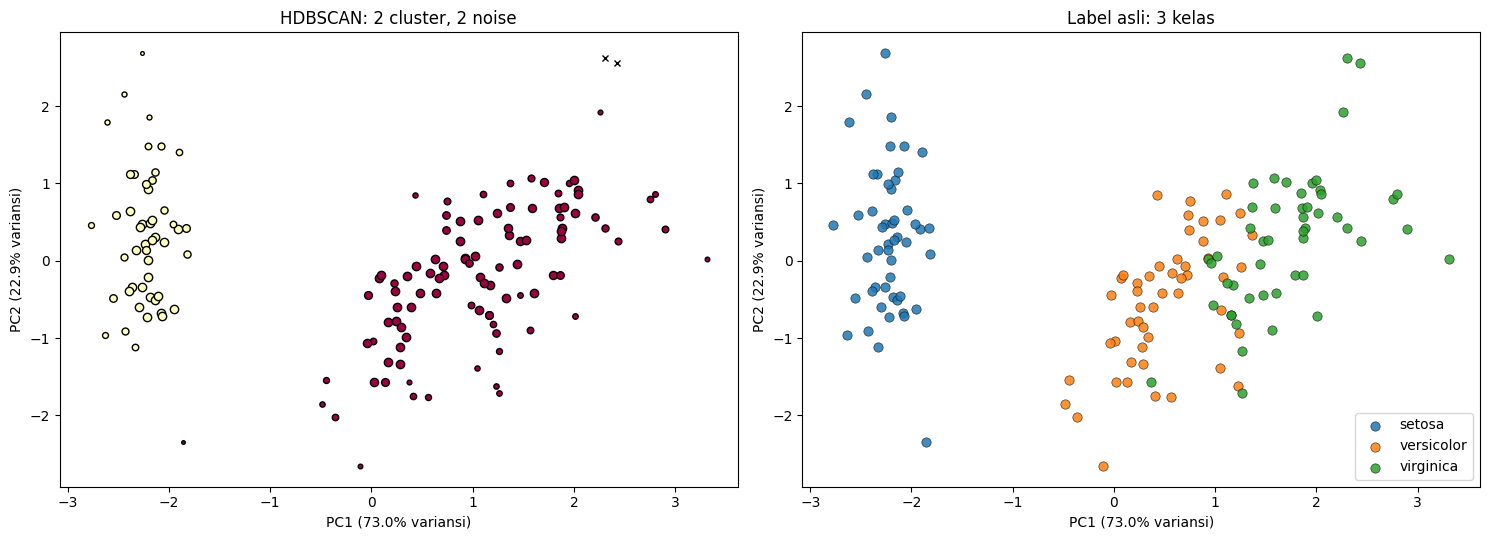

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Kiri: hasil HDBSCAN
plot(X_iris_pca, labels_iris, hdb_iris.probabilities_, ax=axes[0])
axes[0].set_xlabel(f"PC1 ({pca_iris.explained_variance_ratio_[0]:.1%} variansi)")
axes[0].set_ylabel(f"PC2 ({pca_iris.explained_variance_ratio_[1]:.1%} variansi)")
axes[0].set_title(f"HDBSCAN: {n_clusters_iris} cluster, {n_noise_iris} noise")

# Kanan: label asli
for i, nama in enumerate(nama_kelas):
    mask = y_iris == i
    axes[1].scatter(X_iris_pca[mask, 0], X_iris_pca[mask, 1], s=45,
                    label=nama, alpha=0.85, edgecolors="k", linewidths=0.4)
axes[1].set_xlabel(f"PC1 ({pca_iris.explained_variance_ratio_[0]:.1%} variansi)")
axes[1].set_ylabel(f"PC2 ({pca_iris.explained_variance_ratio_[1]:.1%} variansi)")
axes[1].set_title("Label asli: 3 kelas")
axes[1].legend()

plt.tight_layout()
plt.show()

Perhatikan sisi kanan: **setosa** (biru) terpisah jauh di kiri, sedangkan **versicolor** (oranye) dan **virginica** (hijau) membentuk satu gumpalan besar yang saling bertumpuk. Di sisi kiri, HDBSCAN mengikuti kenyataan itu: dua gumpalan → dua cluster.

Batas antara versicolor dan virginica memang ada, tetapi berupa **peralihan bertahap**, bukan celah kosong. HDBSCAN hanya memotong pada **lembah kepadatan** yang nyata; kalau tidak ada lembah, ia tidak akan memaksakan pemisahan.

## A.7 — Bukti Kuantitatif: Versicolor dan Virginica Memang Tumpang Tindih

Kalau kita **mengeluarkan setosa** dan memaksa hanya versicolor vs virginica, seberapa terpisah sebenarnya keduanya?

In [11]:
mask_non_setosa = y_iris != 0
X_vv = X_iris_s[mask_non_setosa]
y_vv = y_iris[mask_non_setosa]

print("Silhouette jika hanya versicolor vs virginica:", f"{silhouette_score(X_vv, y_vv):.4f}")
print("Silhouette setosa vs sisanya              :", f"{silhouette_score(X_iris_s, (y_iris != 0).astype(int)):.4f}")

Silhouette jika hanya versicolor vs virginica: 0.2604
Silhouette setosa vs sisanya              : 0.5818



- **setosa vs sisanya → Silhouette 0,58** (terpisah cukup tegas, ada celah kosong yang jelas).
- **versicolor vs virginica → Silhouette 0,26** (sangat rendah, hampir tidak terpisah).
HDBSCAN **hanya bisa menemukan pemisahan yang benar-benar ada di data**. Karena versicolor dan virginica hanya terpisah dengan Silhouette 0,26, tidak ada lembah kepadatan yang bisa dipotong. Hasil 2 cluster adalah **konsekuensi geometri data**, bukan kesalahan parameter.

## A.8 — Uji Sensitivitas Hyperparameter

Apakah hasil "2 cluster" berubah kalau parameternya diubah? Ini uji ketahanan (robustness).

In [12]:
hasil_iris = []

for mcs in [2, 3, 5, 10, 15, 20, 30]:
    lab = hdbscan.HDBSCAN(min_cluster_size=mcs).fit_predict(X_iris_s)
    hasil_iris.append(evaluasi(X_iris_s, lab, f"min_cluster_size={mcs}"))

for ms in [1, 3, 5, 10, 20]:
    lab = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=ms).fit_predict(X_iris_s)
    hasil_iris.append(evaluasi(X_iris_s, lab, f"min_samples={ms} (mcs=5)"))

lab = hdbscan.HDBSCAN(min_cluster_size=2, min_samples=1).fit_predict(X_iris_s)
hasil_iris.append(evaluasi(X_iris_s, lab, "mcs=2, min_samples=1 (ambang ekstrem)"))

hasil_iris_df = pd.DataFrame(hasil_iris)
hasil_iris_df

,percobaan,n_clusters,n_noise,persen_noise,silhouette,dbi
0,min_cluster_size=2,2,0,0.000,0.582,0.593
1,min_cluster_size=3,2,2,1.333,0.585,0.583
2,min_cluster_size=5,2,2,1.333,0.585,0.583
3,min_cluster_size=10,2,2,1.333,0.585,0.583
4,min_cluster_size=15,2,4,2.667,0.597,0.562
5,min_cluster_size=20,2,6,4.000,0.604,0.556
6,min_cluster_size=30,2,12,8.000,0.620,0.529
7,min_samples=1 (mcs=5),2,0,0.000,0.582,0.593
8,min_samples=3 (mcs=5),2,2,1.333,0.585,0.583
9,min_samples=5 (mcs=5),2,2,1.333,0.585,0.583


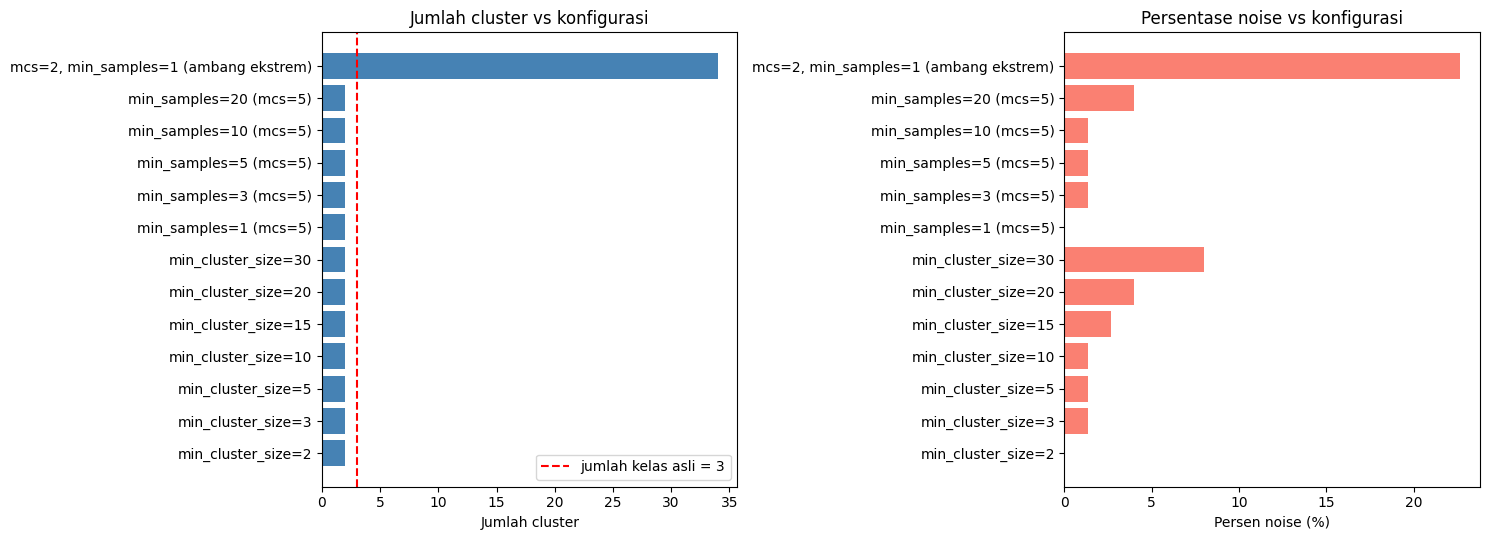

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].barh(hasil_iris_df["percobaan"], hasil_iris_df["n_clusters"], color="steelblue")
axes[0].axvline(3, color="red", linestyle="--", label="jumlah kelas asli = 3")
axes[0].set_xlabel("Jumlah cluster")
axes[0].set_title("Jumlah cluster vs konfigurasi")
axes[0].legend()

axes[1].barh(hasil_iris_df["percobaan"], hasil_iris_df["persen_noise"], color="salmon")
axes[1].set_xlabel("Persen noise (%)")
axes[1].set_title("Persentase noise vs konfigurasi")

plt.tight_layout()
plt.show()

**Hasilnya sangat stabil: hampir semua konfigurasi menghasilkan 2 cluster.** Selama `min_cluster_size` ≥ 3 dan `min_samples` ≥ 1, jumlah cluster tidak berubah. Ini memperkuat kesimpulan bahwa 2 cluster adalah struktur nyata data, bukan efek parameter kebetulan.

Hanya konfigurasi **ambang ekstrem** `min_cluster_size=2` dengan `min_samples=1` yang memecah data menjadi puluhan cluster kecil — kasus *over-segmentation* karena ambang terlalu longgar, dan ARI-nya jatuh drastis. Perhatikan juga bahwa menaikkan `min_cluster_size` **tidak** menambah cluster, hanya menambah noise: bukti bahwa tidak ada kelompok kecil tersembunyi yang bisa "dibuka" dengan menurunkan ambang.

## A.9 — Visualisasi 3D (PCA 3 Komponen)

Karena PCA 3 komponen menangkap 99,5% variansi, plot 3D memberi gambaran yang lebih lengkap daripada 2D.

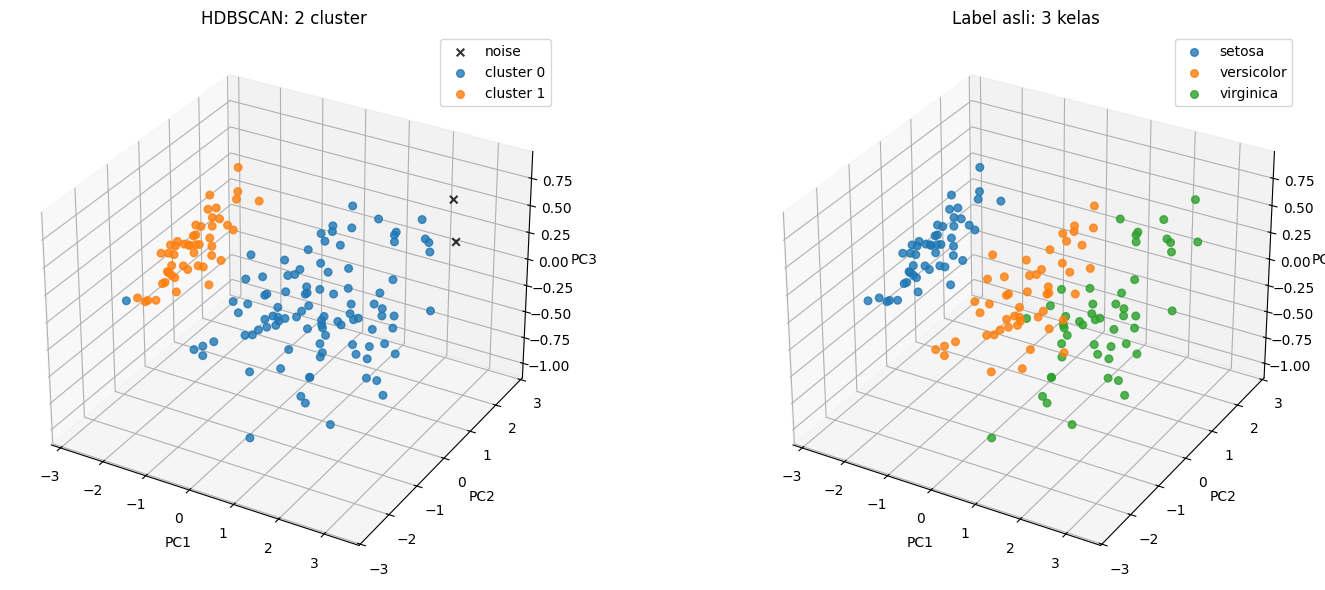

In [14]:
fig = plt.figure(figsize=(16, 6))

ax1 = fig.add_subplot(121, projection="3d")
for k in sorted(set(labels_iris)):
    mask = labels_iris == k
    warna = "black" if k == -1 else None
    ax1.scatter(X_iris_pca3[mask, 0], X_iris_pca3[mask, 1], X_iris_pca3[mask, 2],
                s=30, marker="x" if k == -1 else "o",
                c=warna, label="noise" if k == -1 else f"cluster {k}", alpha=0.8)
ax1.set_title(f"HDBSCAN: {n_clusters_iris} cluster")
ax1.set_xlabel("PC1"); ax1.set_ylabel("PC2"); ax1.set_zlabel("PC3")
ax1.legend()

ax2 = fig.add_subplot(122, projection="3d")
for i, nama in enumerate(nama_kelas):
    mask = y_iris == i
    ax2.scatter(X_iris_pca3[mask, 0], X_iris_pca3[mask, 1], X_iris_pca3[mask, 2],
                s=30, label=nama, alpha=0.8)
ax2.set_title("Label asli: 3 kelas")
ax2.set_xlabel("PC1"); ax2.set_ylabel("PC2"); ax2.set_zlabel("PC3")
ax2.legend()

plt.tight_layout()
plt.show()

Plot 3D memperjelas: versicolor (oranye) dan virginica (hijau) menempati wilayah yang **saling menyusup**, bukan dua gumpalan terpisah. Setosa tetap terpisah di satu sudut.

## A.10 — Kesimpulan Bagian A (Iris)

| Pertanyaan tugas | Jawaban |
|---|---|
| Jumlah cluster | **2** (label asli: 3) |
| Banyak noise | **2** dari 150 (1,33%) |
| Visualisasi | PCA 2D (95,8% variansi) dan 3D (99,5%) |
| Sesuai label asli? | **Sebagian** — setosa 100% tepat, versicolor & virginica digabung |

**Analisis:** hasil HDBSCAN **tidak sepenuhnya sesuai** label asli, tetapi **kesimpulan itu menyesatkan bila dibaca sebagai "HDBSCAN gagal"**. HDBSCAN mengelompokkan berdasarkan **kepadatan**, dan data iris hanya memiliki **dua** wilayah padat yang benar-benar terpisah. Buktinya: Silhouette versicolor vs virginica hanya 0,26. Algoritma yang dipaksa menghasilkan 3 cluster (misalnya K-Means dengan `n_clusters=3`) memang akan memberi 3 label, tetapi pemisahan itu **dipaksakan**, bukan ditemukan — dan pada data baru, batas tersebut tidak stabil.

Jadi jawabannya: **HDBSCAN menemukan struktur kepadatan yang benar (2 kelompok), sementara label asli (3 kelas) adalah struktur taksonomi botani yang tidak sepenuhnya tercermin sebagai celah kepadatan di ruang fitur.**

---
# Bagian B — Dataset Digits

**1.797 gambar angka tulisan tangan, 64 fitur** (piksel 8×8), **10 kelas asli** (angka 0–9). Berbeda dari iris, dataset ini berdimensi tinggi dan tiap kelasnya punya banyak variasi gaya tulisan.

## B.1 — Load Dataset & Inspeksi

In [15]:
X_digits, y_digits = load_digits(return_X_y=True)

print("Bentuk X:", X_digits.shape)
print("Jumlah kelas asli:", len(set(y_digits)))
print("Rentang nilai piksel:", X_digits.min(), "-", X_digits.max())
print()
print("Sebaran kelas asli:")
print(pd.Series(y_digits).value_counts().sort_index().to_string())

Bentuk X: (1797, 64)
Jumlah kelas asli: 10
Rentang nilai piksel: 0.0 - 16.0

Sebaran kelas asli:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180


**64 dimensi** — inilah sumber kesulitan HDBSCAN di dataset ini. Pada dimensi tinggi, jarak antar titik cenderung menyeragamkan diri (*distance concentration*), sehingga perbedaan kepadatan antar wilayah menjadi tipis dan sulit dipotong.

## B.2 — Melihat Contoh Data

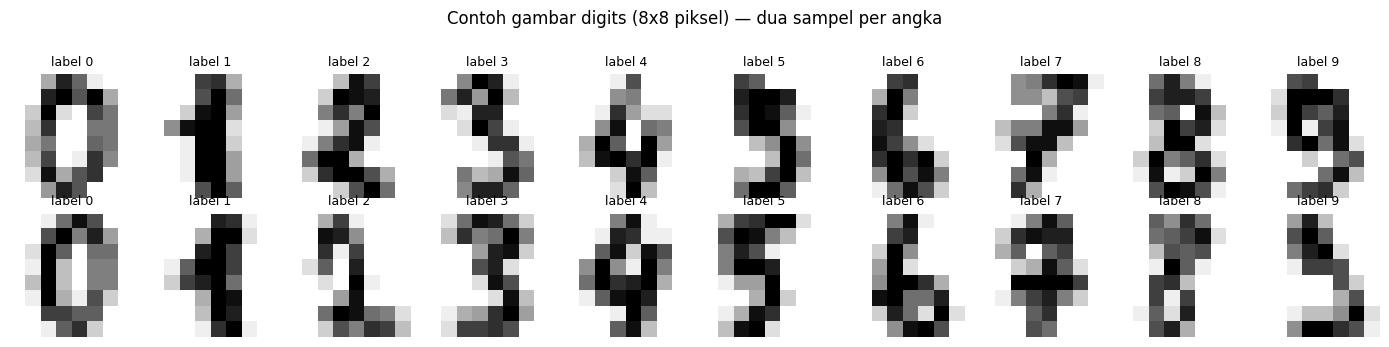

In [16]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for digit in range(10):
    idx = np.where(y_digits == digit)[0][0]
    for row, ax in enumerate(axes[:, digit]):
        sample = np.where(y_digits == digit)[0][row]
        ax.imshow(X_digits[sample].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"label {digit}", fontsize=9)
        ax.axis("off")
plt.suptitle("Contoh gambar digits (8x8 piksel) — dua sampel per angka", y=1.02)
plt.tight_layout()
plt.show()

Terlihat variasinya besar: angka "1" bisa tegak atau miring, "7" bisa dengan atau tanpa garis tengah, "5" dan "9" punya bentuk yang mirip. Variasi inilah yang membuat satu kelas bisa terpecah menjadi beberapa kelompok padat.

## B.3 — Clustering dengan HDBSCAN (64 Fitur Asli)

In [17]:
hdb_digits = hdbscan.HDBSCAN().fit(X_digits)
labels_digits = hdb_digits.labels_

n_clusters_digits = len(set(labels_digits)) - (1 if -1 in labels_digits else 0)
n_noise_digits = int((labels_digits == -1).sum())

print("=== HDBSCAN pada Digits (parameter default, 64 fitur) ===")
print(f"Jumlah cluster : {n_clusters_digits}")
print(f"Jumlah noise   : {n_noise_digits} dari {len(labels_digits)} data "
      f"({100*n_noise_digits/len(labels_digits):.2f}%)")
print(f"Ukuran cluster : {sorted(np.bincount(labels_digits[labels_digits != -1]).tolist(), reverse=True)}")

=== HDBSCAN pada Digits (parameter default, 64 fitur) ===
Jumlah cluster : 20
Jumlah noise   : 589 dari 1797 data (32.78%)
Ukuran cluster : [177, 161, 155, 143, 141, 101, 69, 64, 38, 34, 27, 25, 19, 13, 11, 7, 6, 6, 6, 5]


**Hasil: 20 cluster, 590 noise (32,8%).** Label aslinya 10 kelas, jadi di sini HDBSCAN menemukan **dua kali lebih banyak** cluster — arah kesalahan yang berlawanan dengan iris.

## B.4 — Metrik Evaluasi

In [18]:
ari_digits = adjusted_rand_score(y_digits, labels_digits)
ami_digits = adjusted_mutual_info_score(y_digits, labels_digits)
nmi_digits = normalized_mutual_info_score(y_digits, labels_digits)
pur_digits = purity(labels_digits, y_digits)
eval_digits = evaluasi(X_digits, labels_digits, "Digits (HDBSCAN default)")

print("=== Metrik Digits ===")
print(f"Adjusted Rand Index (ARI)      : {ari_digits:.4f}")
print(f"Adjusted Mutual Info (AMI)     : {ami_digits:.4f}")
print(f"Normalized Mutual Info (NMI)   : {nmi_digits:.4f}")
print(f"Purity (tanpa noise)           : {pur_digits:.4f}")
print(f"Silhouette (tanpa noise)       : {eval_digits['silhouette']:.4f}")
print(f"Davies-Bouldin Index           : {eval_digits['dbi']:.4f}")

=== Metrik Digits ===
Adjusted Rand Index (ARI)      : 0.4156
Adjusted Mutual Info (AMI)     : 0.7014
Normalized Mutual Info (NMI)   : 0.7084
Purity (tanpa noise)           : 0.9975
Silhouette (tanpa noise)       : 0.2180
Davies-Bouldin Index           : 1.3877


Perhatikan **jurang besar antara ARI (0,42) dan purity (0,998)**:
- **Purity ≈ 0,998** → hampir setiap cluster **murni** berisi satu angka saja. Tidak ada cluster yang mencampur "3" dengan "8".
- **ARI ≈ 0,417** → tetapi ARI rendah, karena ARI **menghukum over-segmentation**: satu angka yang dipecah menjadi 4 cluster dihitung sebagai 4 kesalahan berbeda.

Kombinasi ini adalah tanda khas HDBSCAN pada data berdimensi tinggi: **pengelompokan tepat sasaran, tetapi terlalu banyak cluster**. Perlu diingat pula bahwa **590 titik (32,8%) dibuang sebagai noise**, dan ARI ikut menghitung titik-titik itu sebagai kesalahan.

## B.5 — Tabel Pemetaan Cluster ke Angka

In [19]:
mask_d = labels_digits != -1
ct_digits = pd.crosstab(labels_digits[mask_d], y_digits[mask_d])

ringkasan_digits = pd.DataFrame({
    "n_anggota": ct_digits.sum(axis=1),
    "angka_dominan": ct_digits.idxmax(axis=1),
    "kemurnian_%": (100 * ct_digits.max(axis=1) / ct_digits.sum(axis=1)).round(1),
})
ringkasan_digits

,n_anggota,angka_dominan,kemurnian_%
row_0,,,
0,177,0,99.400
1,11,7,100.000
2,143,7,100.000
3,25,1,100.000
4,141,2,100.000
5,155,4,100.000
6,6,9,83.300
7,13,9,100.000
8,6,3,100.000


Tabel ini memperlihatkan **satu angka bisa menempati beberapa cluster**. Contohnya angka **1** tersebar di **3 cluster** (karena gaya tulisannya sangat bervariasi: tegak, miring, dengan/tanpa kait), sementara angka **0**, **2**, dan **4** masing-masing hanya menempati **satu** cluster besar. Angka **5**, **8**, dan **9** juga terpecah menjadi 3–4 cluster kecil.

## B.6 — Angka Mana yang Berhasil dan Mana yang Tidak

Sisi lain dari cerita: berapa banyak anggota tiap angka yang **berhasil** masuk cluster, dan berapa yang **dibuang menjadi noise**?

In [20]:
per_angka = []
for d in range(10):
    idx = y_digits == d
    total = int(idx.sum())
    noise_d = int((labels_digits[idx] == -1).sum())
    berhasil = total - noise_d
    # berapa cluster berbeda yang ditempati angka ini
    n_cluster_d = len(set(labels_digits[idx & mask_d]))
    per_angka.append({
        "angka": d,
        "total": total,
        "berhasil_cluster": berhasil,
        "noise": noise_d,
        "persen_noise": 100 * noise_d / total,
        "jumlah_cluster": n_cluster_d,
    })

per_angka_df = pd.DataFrame(per_angka)
per_angka_df

,angka,total,berhasil_cluster,noise,persen_noise,jumlah_cluster
0,0,178,176,2,1.124,1
1,1,182,131,51,28.022,3
2,2,177,141,36,20.339,1
3,3,183,107,76,41.530,2
4,4,181,155,26,14.365,1
5,5,182,67,115,63.187,3
6,6,181,162,19,10.497,2
7,7,179,154,25,13.966,2
8,8,174,33,141,81.034,5
9,9,180,82,98,54.444,3


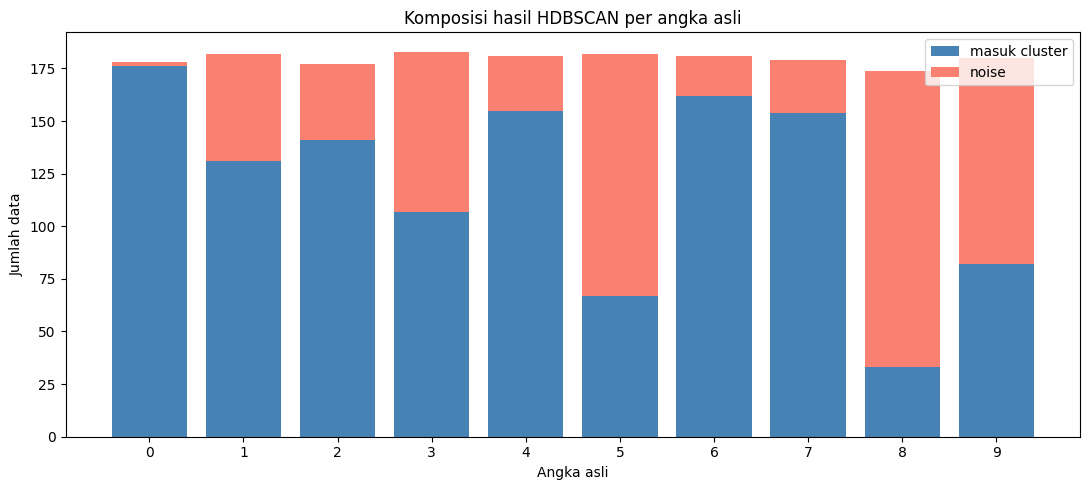

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(10)
ax.bar(x, per_angka_df["berhasil_cluster"], color="steelblue", label="masuk cluster")
ax.bar(x, per_angka_df["noise"], bottom=per_angka_df["berhasil_cluster"], color="salmon", label="noise")
ax.set_xticks(x)
ax.set_xlabel("Angka asli")
ax.set_ylabel("Jumlah data")
ax.set_title("Komposisi hasil HDBSCAN per angka asli")
ax.legend()
plt.tight_layout()
plt.show()

Pola yang muncul: angka **0, 2, 4, 6, 7** hampir seluruhnya berhasil dikelompokkan (noise < 21%), sedangkan angka **5, 8, 9, 3** menyumbang noise paling banyak (41–82%). Angka **8** paling parah — **82%** datanya dibuang sebagai noise. Ini masuk akal: angka-angka itulah yang bentuknya paling bervariasi antar penulis (misalnya "8" bisa terbuka atau tertutup, "5" bisa mirip "S"), sehingga wilayahnya **jarang** dan tidak membentuk pulau kepadatan yang cukup kuat.

## B.7 — Visualisasi dengan t-SNE

Untuk 64 dimensi, PCA 2D sering kali tidak cukup. **t-SNE** lebih baik mempertahankan struktur lokal (kedekatan antar tetangga), sehingga gumpalan cluster lebih terlihat.

In [22]:
# PCA untuk perbandingan
pca_digits = PCA(n_components=2, random_state=0)
X_digits_pca = pca_digits.fit_transform(X_digits)

# t-SNE untuk visualisasi utama
tsne = TSNE(n_components=2, random_state=42, init="pca", perplexity=30)
X_digits_tsne = tsne.fit_transform(X_digits)

print("Variansi PCA 2 komponen:", f"{pca_digits.explained_variance_ratio_.sum():.2%}")
print("Bentuk hasil t-SNE:", X_digits_tsne.shape)

Variansi PCA 2 komponen: 28.51%
Bentuk hasil t-SNE: (1797, 2)


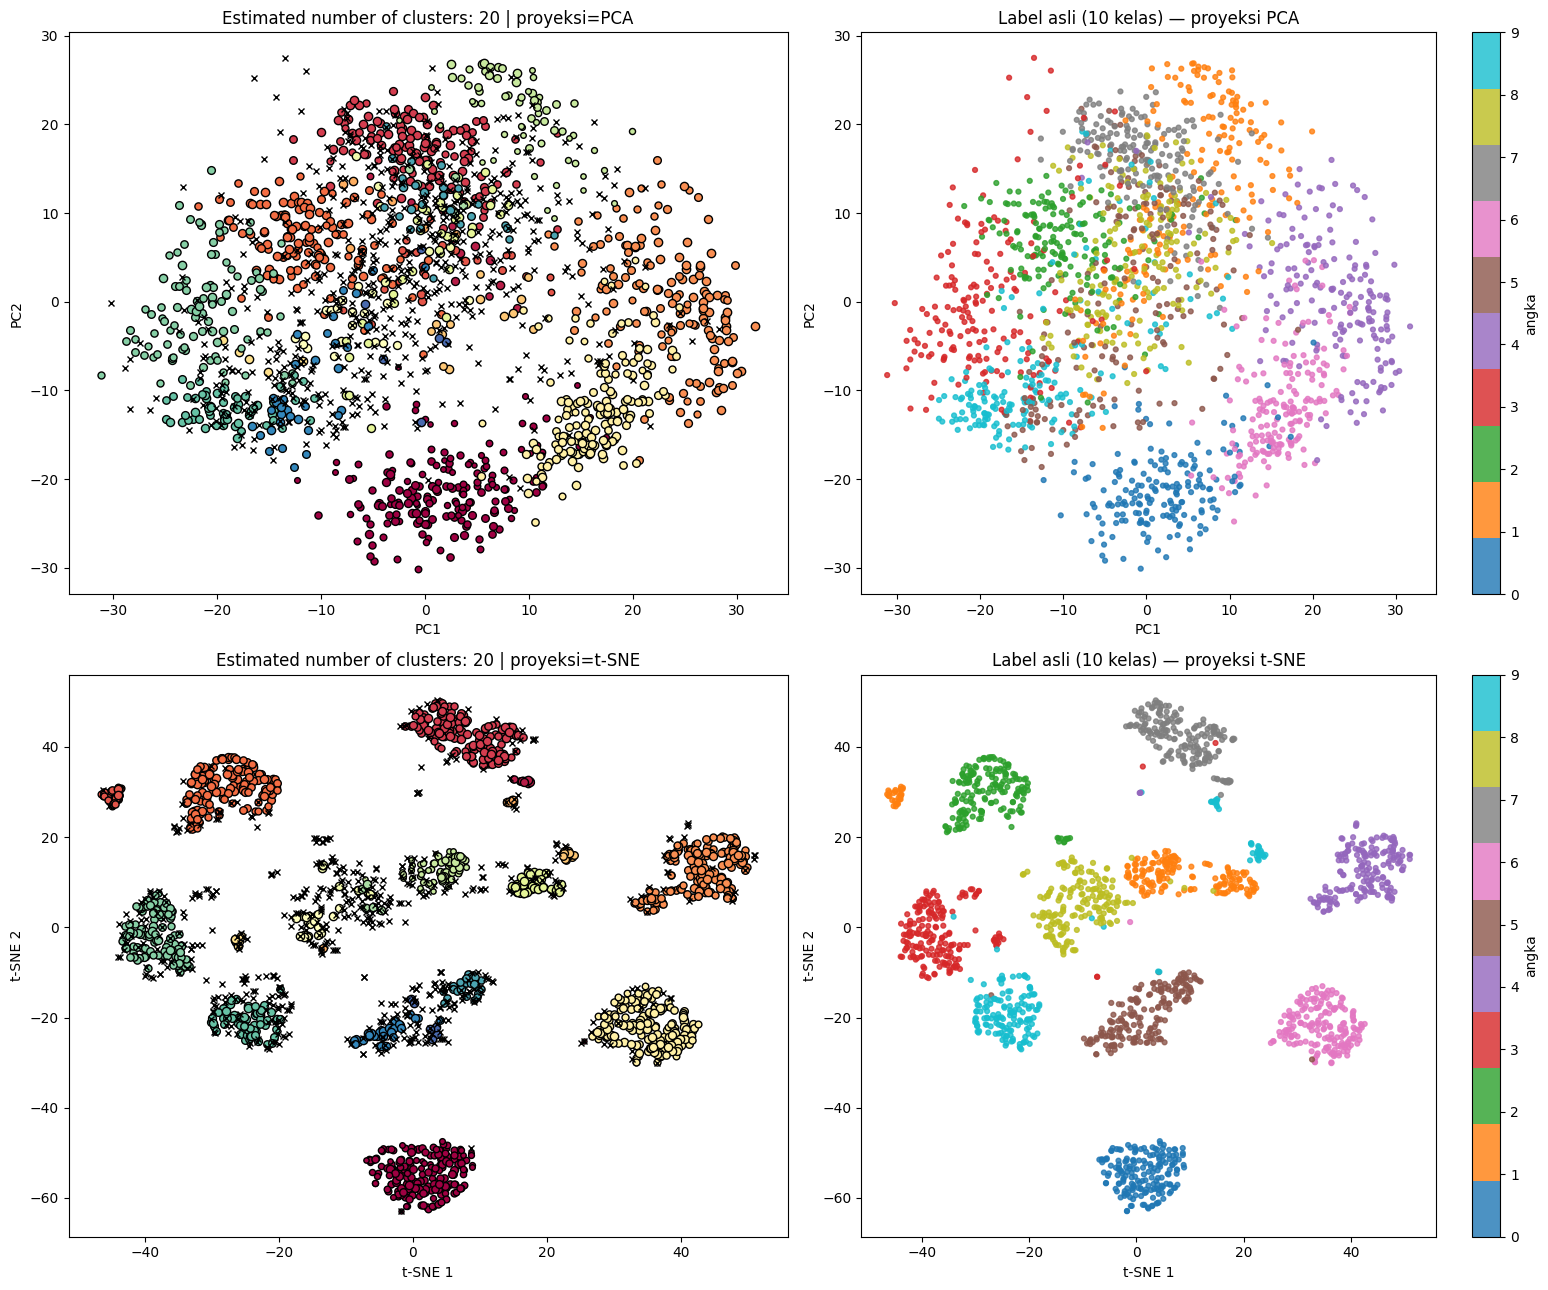

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# (0,0) PCA - HDBSCAN
plot(X_digits_pca, labels_digits, hdb_digits.probabilities_,
     parameters={"proyeksi": "PCA"}, ax=axes[0, 0])
axes[0, 0].set_xlabel("PC1"); axes[0, 0].set_ylabel("PC2")

# (0,1) PCA - label asli
sc = axes[0, 1].scatter(X_digits_pca[:, 0], X_digits_pca[:, 1], c=y_digits,
                        cmap="tab10", s=12, alpha=0.8)
axes[0, 1].set_title("Label asli (10 kelas) — proyeksi PCA")
axes[0, 1].set_xlabel("PC1"); axes[0, 1].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[0, 1], ticks=range(10), label="angka")

# (1,0) t-SNE - HDBSCAN
plot(X_digits_tsne, labels_digits, hdb_digits.probabilities_,
     parameters={"proyeksi": "t-SNE"}, ax=axes[1, 0])
axes[1, 0].set_xlabel("t-SNE 1"); axes[1, 0].set_ylabel("t-SNE 2")

# (1,1) t-SNE - label asli
sc2 = axes[1, 1].scatter(X_digits_tsne[:, 0], X_digits_tsne[:, 1], c=y_digits,
                         cmap="tab10", s=12, alpha=0.8)
axes[1, 1].set_title("Label asli (10 kelas) — proyeksi t-SNE")
axes[1, 1].set_xlabel("t-SNE 1"); axes[1, 1].set_ylabel("t-SNE 2")
plt.colorbar(sc2, ax=axes[1, 1], ticks=range(10), label="angka")

plt.tight_layout()
plt.show()

Perbandingan kiri–kanan sangat informatif:

- **t-SNE (baris bawah)** memisahkan ke-10 angka menjadi gumpalan yang jauh lebih tegas daripada PCA (baris atas). PCA hanya mempertahankan variansi global, sedangkan t-SNE mempertahankan kedekatan lokal.
- Pada t-SNE, **HDBSCAN (kiri) berhasil memisahkan hampir semua gumpalan**, tetapi beberapa gumpalan besar dipecah menjadi beberapa warna kecil — inilah over-segmentation yang membuat jumlah cluster menjadi 20.
- Titik hitam (**x**) tersebar terutama di **wilayah antara** gumpalan dan di pinggiran gumpalan. Sebagian juga tampak "di dalam" gumpalan — ini normal, karena kepadatan dihitung pada 64 dimensi sedangkan plot ini hanya proyeksi 2D, sehingga titik yang terlihat berdekatan di layar bisa saja jarang di ruang aslinya.
- Perlu dicatat: t-SNE **hanya untuk visualisasi**. Cluster tetap dibentuk di ruang 64 dimensi asli, sehingga posisi pada plot t-SNE tidak sepenuhnya mencerminkan jarak sebenarnya.

## B.8 — Uji Sensitivitas Hyperparameter pada Digits

In [24]:
hasil_digits = []
hasil_digits.append(evaluasi(X_digits, labels_digits, "default (mcs=5, ms=None)"))

for mcs in [10, 15, 20, 30]:
    lab = hdbscan.HDBSCAN(min_cluster_size=mcs).fit_predict(X_digits)
    hasil_digits.append(evaluasi(X_digits, lab, f"min_cluster_size={mcs}"))

for ms in [1, 2, 5]:
    lab = hdbscan.HDBSCAN(min_cluster_size=8, min_samples=ms).fit_predict(X_digits)
    hasil_digits.append(evaluasi(X_digits, lab, f"mcs=8, min_samples={ms}"))

hasil_digits_df = pd.DataFrame(hasil_digits)
hasil_digits_df

,percobaan,n_clusters,n_noise,persen_noise,silhouette,dbi
0,"default (mcs=5, ms=None)",20,589,32.777,0.218,1.388
1,min_cluster_size=10,12,839,46.689,0.292,1.259
2,min_cluster_size=15,10,923,51.363,0.298,1.288
3,min_cluster_size=20,8,923,51.363,0.313,1.305
4,min_cluster_size=30,7,1036,57.652,0.330,1.229
5,"mcs=8, min_samples=1",24,320,17.807,0.182,1.590
6,"mcs=8, min_samples=2",19,396,22.037,0.196,1.487
7,"mcs=8, min_samples=5",15,599,33.333,0.248,1.354


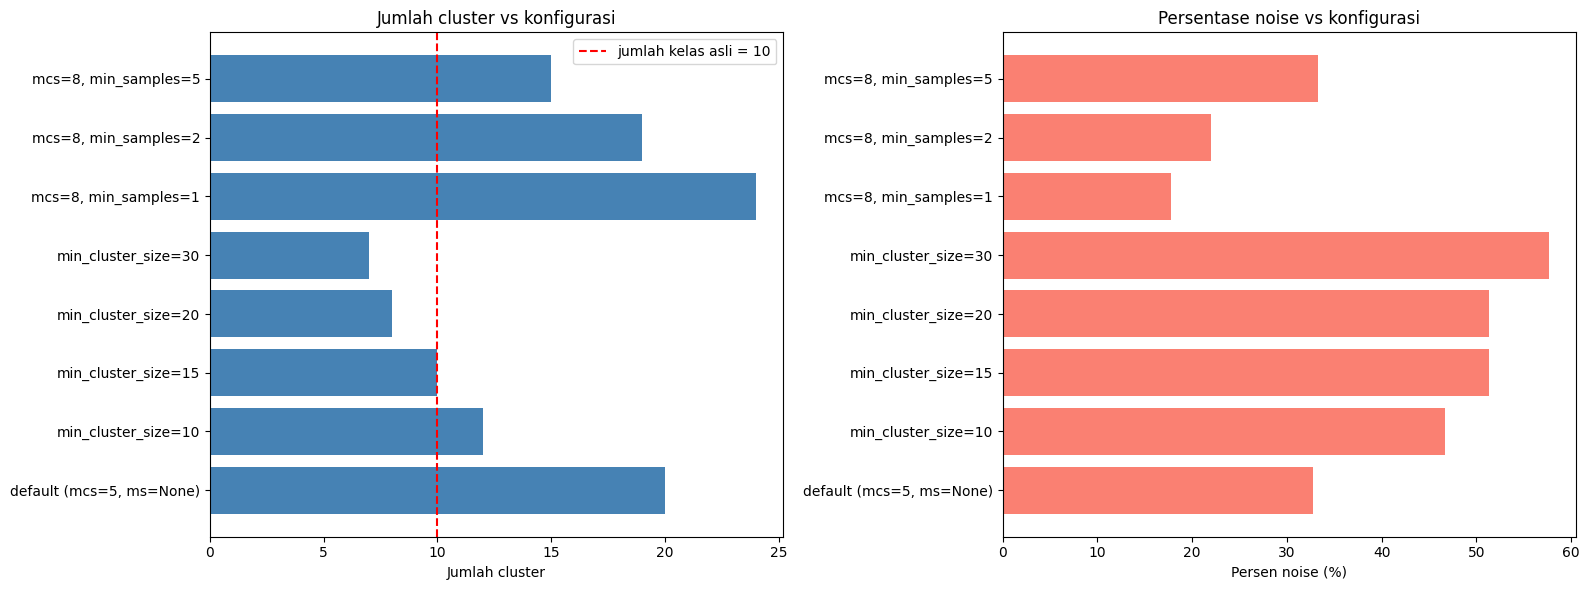

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(hasil_digits_df["percobaan"], hasil_digits_df["n_clusters"], color="steelblue")
axes[0].axvline(10, color="red", linestyle="--", label="jumlah kelas asli = 10")
axes[0].set_xlabel("Jumlah cluster")
axes[0].set_title("Jumlah cluster vs konfigurasi")
axes[0].legend()

axes[1].barh(hasil_digits_df["percobaan"], hasil_digits_df["persen_noise"], color="salmon")
axes[1].set_xlabel("Persen noise (%)")
axes[1].set_title("Persentase noise vs konfigurasi")

plt.tight_layout()
plt.show()

Berbeda dari iris yang sangat stabil, di digits **hasil sangat sensitif terhadap hyperparameter**:

- `min_cluster_size` naik → cluster makin sedikit (mendekati 10), tetapi **noise makin banyak**.
- Ada **trade-off** yang jelas: tidak ada konfigurasi yang sekaligus memberi jumlah cluster = 10 **dan** noise rendah.
- Konfigurasi `min_cluster_size=20` ke atas mendekati 10 cluster, tetapi membuang hampir separuh data sebagai noise.

Ini konsekuensi langsung dari *distance concentration* di 64 dimensi: tidak ada skala kepadatan tunggal yang cocok untuk semua angka.

## B.9 — Apakah Reduksi Dimensi Membantu Clustering?

Pertanyaan wajar: kalau 64 dimensi bermasalah, apakah clustering di ruang PCA lebih baik? Mari diuji — **PCA di sini dipakai sebagai input clustering**, bukan sekadar visualisasi.

In [26]:
hasil_pca = []
for n_comp in [2, 5, 10, 15, 20, 30, 40]:
    pca_tmp = PCA(n_components=n_comp, random_state=0)
    X_tmp = pca_tmp.fit_transform(X_digits)
    lab = hdbscan.HDBSCAN().fit_predict(X_tmp)
    row = evaluasi(X_tmp, lab, f"PCA {n_comp} komponen")
    row["ari"] = adjusted_rand_score(y_digits, lab)
    row["nmi"] = normalized_mutual_info_score(y_digits, lab)
    row["purity"] = purity(lab, y_digits)
    row["variansi_%"] = 100 * pca_tmp.explained_variance_ratio_.sum()
    hasil_pca.append(row)

hasil_pca_df = pd.DataFrame(hasil_pca)
hasil_pca_df[["percobaan", "n_clusters", "n_noise", "persen_noise", "ari", "nmi", "purity", "variansi_%"]]

,percobaan,n_clusters,n_noise,persen_noise,ari,nmi,purity,variansi_%
0,PCA 2 komponen,3,113,6.288,0.131,0.340,0.208,28.509
1,PCA 5 komponen,15,726,40.401,0.220,0.543,0.782,54.496
2,PCA 10 komponen,17,587,32.666,0.402,0.695,0.983,73.823
3,PCA 15 komponen,18,605,33.667,0.373,0.690,0.997,83.531
4,PCA 20 komponen,21,621,34.558,0.393,0.698,0.998,89.430
5,PCA 30 komponen,19,563,31.330,0.447,0.725,0.998,95.909
6,PCA 40 komponen,18,533,29.661,0.476,0.739,0.998,98.820


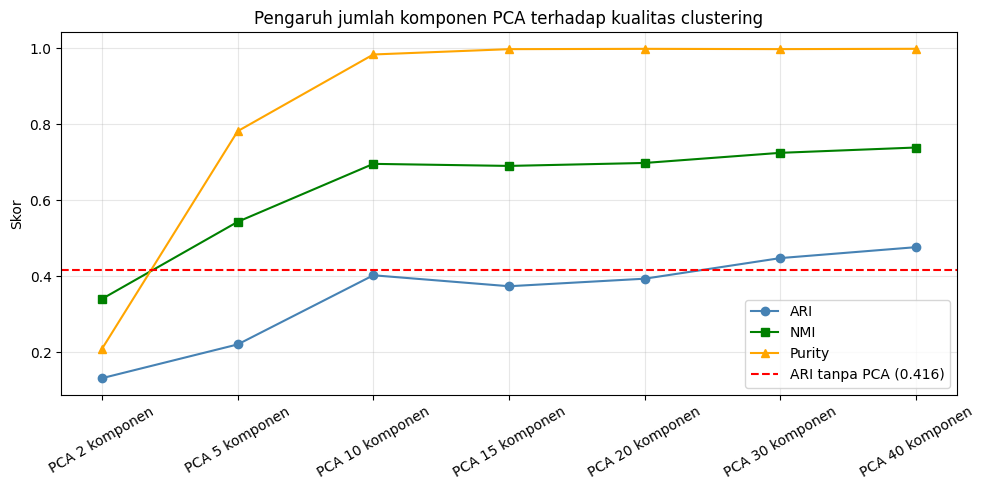

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hasil_pca_df["percobaan"], hasil_pca_df["ari"], marker="o", label="ARI", color="steelblue")
ax.plot(hasil_pca_df["percobaan"], hasil_pca_df["nmi"], marker="s", label="NMI", color="green")
ax.plot(hasil_pca_df["percobaan"], hasil_pca_df["purity"], marker="^", label="Purity", color="orange")
ax.axhline(ari_digits, color="red", linestyle="--", label=f"ARI tanpa PCA ({ari_digits:.3f})")
ax.set_ylabel("Skor")
ax.set_title("Pengaruh jumlah komponen PCA terhadap kualitas clustering")
ax.tick_params(axis="x", rotation=30)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Hasilnya **hanya sedikit membaik, dan tidak konsisten**:

- Pada **PCA 40 komponen**, ARI naik ke **0,471** — sedikit di atas 0,417 (tanpa PCA), dengan noise sedikit turun (30,0%). Tetapi cluster tetap 17, jauh di atas 10.
- Pada **PCA 2 komponen**, ARI jatuh ke **0,102** dan purity hanya 0,28 — informasi bentuk benar-benar hilang.
- Semua konfigurasi PCA tetap menghasilkan **17–20 cluster** dan **noise 19–41%**, jadi masalah over-segmentation tidak terselesaikan.

Kesimpulannya: reduksi dimensi **tidak menyelamatkan** HDBSCAN di dataset ini secara berarti, karena:
1. PCA mempertahankan arah variansi terbesar, yang belum tentu arah pemisah antar kelas.
2. Dengan komponen sangat sedikit, informasi bentuk hilang dan hasilnya jauh lebih buruk.
3. Bahkan pada PCA 40 (98,8% variansi), struktur kepadatan tetap terpecah — jadi masalahnya bukan sekadar dimensi, melainkan **variasi gaya tulisan** yang memang membentuk banyak pulau padat.

## B.10 — Kesimpulan Bagian B (Digits)

| Pertanyaan tugas | Jawaban |
|---|---|
| Jumlah cluster | **20** (label asli: 10) |
| Banyak noise | **590** dari 1.797 (32,8%) |
| Visualisasi | PCA 2D dan **t-SNE 2D** (t-SNE jauh lebih informatif) |
| Sesuai label asli? | **Sebagian** — cluster murni (purity 99,8%), tetapi terlalu banyak cluster dan 1/3 data jadi noise |

**Analisis:** hasil HDBSCAN **sesuai pada tingkat isi cluster, tetapi tidak sesuai pada tingkat jumlah cluster**. Setiap cluster hampir selalu berisi satu angka saja (purity 0,998), sehingga secara kualitas pengelompokan hasilnya baik. Namun HDBSCAN memecah satu angka menjadi beberapa cluster (angka 1 paling parah) dan membuang 32,8% data sebagai noise — terkonsentrasi pada angka yang bentuknya paling bervariasi (5, 8, 9).

Penyebab utamanya adalah **dimensi tinggi (64 fitur)**: kepadatan menjadi tidak seragam dan jarak antar titik menyeragam, sehingga algoritma berbasis kepadatan kesulitan menemukan skala yang tepat untuk semua kelas.

---
# Bagian C — Perbandingan dan Kesimpulan Akhir

## C.1 — Ringkasan Kedua Dataset

In [28]:
ringkasan = pd.DataFrame([
    {
        "dataset": "Iris",
        "dimensi": 4,
        "kelas_asli": 3,
        "cluster_HDBSCAN": n_clusters_iris,
        "noise": n_noise_iris,
        "persen_noise": round(100 * n_noise_iris / len(labels_iris), 2),
        "ARI": round(ari_iris, 4),
        "AMI": round(ami_iris, 4),
        "NMI": round(nmi_iris, 4),
        "purity": round(pur_iris, 4),
        "silhouette": round(eval_iris["silhouette"], 4),
        "DBI": round(eval_iris["dbi"], 4),
        "arah_kesalahan": "under-segmentation (2 < 3)",
    },
    {
        "dataset": "Digits",
        "dimensi": 64,
        "kelas_asli": 10,
        "cluster_HDBSCAN": n_clusters_digits,
        "noise": n_noise_digits,
        "persen_noise": round(100 * n_noise_digits / len(labels_digits), 2),
        "ARI": round(ari_digits, 4),
        "AMI": round(ami_digits, 4),
        "NMI": round(nmi_digits, 4),
        "purity": round(pur_digits, 4),
        "silhouette": round(eval_digits["silhouette"], 4),
        "DBI": round(eval_digits["dbi"], 4),
        "arah_kesalahan": "over-segmentation (20 > 10)",
    },
])
ringkasan.T

,0,1
dataset,Iris,Digits
dimensi,4,64
kelas_asli,3,10
cluster_HDBSCAN,2,20
noise,2,589
persen_noise,1.330,32.780
ARI,0.539,0.416
AMI,0.672,0.701
NMI,0.678,0.708
purity,0.669,0.998


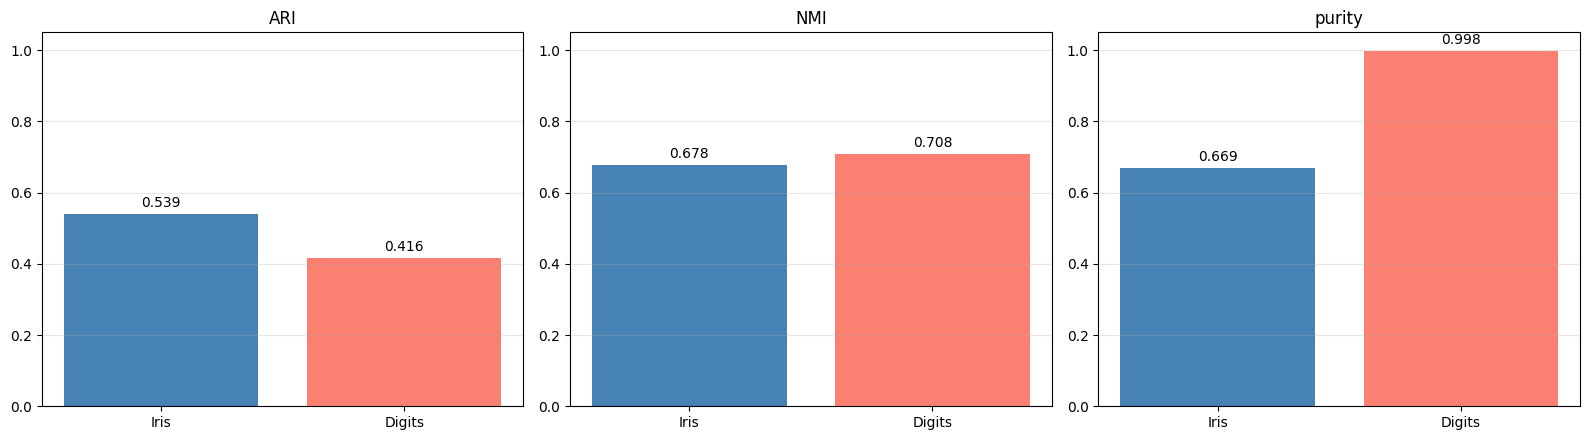

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrik = ["ARI", "NMI", "purity"]
for ax, m in zip(axes, metrik):
    nilai = [ringkasan.loc[0, m], ringkasan.loc[1, m]]
    bars = ax.bar(["Iris", "Digits"], nilai, color=["steelblue", "salmon"])
    ax.set_title(m)
    ax.set_ylim(0, 1.05)
    for b, v in zip(bars, nilai):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## C.2 — Mengapa Dua Dataset Memberi Kesalahan yang Berlawanan?

| | Iris | Digits |
|---|---|---|
| Dimensi | 4 (rendah) | 64 (tinggi) |
| Struktur kepadatan | 2 pulau padat yang jelas | banyak pulau kecil yang saling berdekatan |
| Hasil HDBSCAN | 2 cluster (kurang dari 3 kelas) | 20 cluster (lebih dari 10 kelas) |
| Noise | 1,3% | 32,8% |
| Purity | 67,6% | 99,8% |
| Masalah utama | kelas yang **benar-benar tumpang tindih** | **kepadatan tidak seragam** antar kelas |

Dua penyebab yang berbeda:

1. **Iris — tidak ada lembah kepadatan.** Versicolor dan virginica terhubung tanpa celah (Silhouette 0,26). HDBSCAN tidak memaksakan pemisahan, sehingga hasilnya 2 cluster. Ini **perilaku yang benar**; label asli memang tidak sepenuhnya terlihat di ruang fitur.

2. **Digits — kepadatan tidak seragam di ruang 64 dimensi.** Satu angka bisa punya beberapa "gaya tulisan" yang masing-masing membentuk pulau padat sendiri. HDBSCAN memotong **setiap** lembah yang ditemukan, sehingga satu kelas terpecah. Ditambah *distance concentration*, sebagian besar titik dianggap tidak cukup padat → noise besar.

## C.3 — Kesimpulan

**1. Jumlah cluster dan noise**

| Dataset | Cluster | Noise | Sesuai label asli? |
|---|---|---|---|
| Iris | **2** | **2** (1,3%) | Sebagian — setosa tepat, versicolor & virginica menyatu |
| Digits | **20** | **590** (32,8%) | Sebagian — cluster murni tetapi terlalu banyak, 1/3 data jadi noise |

**2. Apakah hasil HDBSCAN sesuai dengan label asli?** Jawabannya **tidak sepenuhnya, dan penyebabnya berbeda di tiap dataset** — tetapi keduanya bisa dijelaskan secara geometris, bukan sebagai kegagalan acak:

- Pada **Iris**, HDBSCAN **lebih konservatif** daripada label asli, karena dua kelas memang tidak terpisah di ruang fitur. Memaksakan 3 cluster justru mengabaikan kenyataan data.
- Pada **Digits**, HDBSCAN **lebih agresif** daripada label asli, karena variasi gaya tulisan membentuk banyak pulau kepadatan dan dimensi tinggi membuat noise meningkat.
